# VGGT depth-head fine-tuning — clean notebook

**Project:** fine-tune only the depth head of VGGT on Virtual KITTI 2 (synthetic driving) and test whether it improves depth on real KITTI (unseen).

| Part | What | When to run |
|---|---|---|
| A | Setup | **every session** |
| B | Phase 1 — replication on the example scene | once (for the report) |
| C | Data — VKitti (train/val) + real-KITTI subset | once (saved on Drive) |
| D | Evaluation code | every session |
| E | Baseline evaluation ① ② | once |
| F | Fine-tuning (4 VKitti scenes) | once |
| G | Fine-tuned evaluation ③ ④ | after F |
| H | View-count ablation + summary | after G |

### Fixes compared to the previous notebook
1. **`aspects` = height/width** in VGGT's code. The old `[0.3, 3.5]` produced images up to 3.5× taller than wide. Now `[0.28, 0.34]`, around KITTI's ≈0.30.
2. **`img_nums` was never set** → default 2–24 frames per sample while `max_img_per_gpu` was 4 → out-of-memory. Now `[2, 8]`.
3. **Training resolution** was 224 but evaluation used 518. Now both use **518**.
4. **Evaluation was single-view** (one image at a time). Now **multi-view windows of 8 frames**.
5. **No `pip install -e .`**: it downgraded NumPy and broke TensorBoard. The repo is used via `PYTHONPATH` instead.
6. The config is **written from scratch** by this notebook (no patching of old files, no debug prints).
7. A check that the **fine-tuned depth-head weights really load**.

**Runtime:** `Runtime → Change runtime type → GPU`. T4 works; A100/L4 is faster.

# Part A — Setup (every session)

### A1. GPU

In [1]:
import torch
print(torch.__version__, '| cuda:', torch.cuda.is_available())
GPU_NAME = torch.cuda.get_device_name(0)
GPU_MEM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
BF16_OK = torch.cuda.get_device_capability()[0] >= 8
print(f'{GPU_NAME} | {GPU_MEM_GB:.0f} GB | bfloat16 supported: {BF16_OK}')

2.11.0+cu130 | cuda: True
NVIDIA A100-SXM4-40GB | 42 GB | bfloat16 supported: True


### A2. Google Drive and paths

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, shutil, subprocess, sys
PROJECT      = '/content/drive/MyDrive/vggt-depth-finetune'
DATA_DRIVE   = f'{PROJECT}/data'
RAW_TARS     = f'{DATA_DRIVE}/raw_tars'                 # vkitti_rgb.tar, vkitti_depth.tar, vkitti_textgt.tar.gz
KITTI_ROOT   = f'{DATA_DRIVE}/kitti_subset'             # real KITTI subset (Part C2)
PRETRAINED_CKPT = f'{DATA_DRIVE}/vggt_1b_checkpoint.pt' # pretrained weights as a state_dict (Part F1)
CKPT_DIR     = f'{PROJECT}/checkpoints'
RESULTS_DIR  = f'{PROJECT}/results'
FIG_DIR      = f'{PROJECT}/figures'
LOG_DIR      = f'{PROJECT}/logs'

# local (fast) copies used during the session
VKITTI_TRAIN = '/content/vkitti_train'
VKITTI_VAL   = '/content/vkitti_val'
REPO         = '/content/vggt_repo'

for d in [KITTI_ROOT, CKPT_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)
print('Drive project folder:', sorted(os.listdir(PROJECT)))

Mounted at /content/drive
Drive project folder: ['checkpoints', 'checkpoints_backup', 'data', 'figures', 'logs', 'results', 'vggt']


### A3. Code and dependencies
A fresh clone of the official repo every session. No `pip install -r requirements.txt` (pinned torch) and no `pip install -e .` (pins old NumPy). The repo is put on `PYTHONPATH` instead, which also reaches the training subprocess.

In [3]:
if not os.path.isdir(REPO):
    subprocess.run(['git', 'clone', '-q', 'https://github.com/facebookresearch/vggt.git', REPO], check=True)
!pip install -q einops huggingface_hub safetensors hydra-core omegaconf fvcore iopath wcmatch remotezip tensorboard

sys.path.insert(0, REPO)
os.environ['PYTHONPATH'] = REPO + ':' + os.environ.get('PYTHONPATH', '')

import numpy as np
from vggt.models.vggt import VGGT
from vggt.utils.load_fn import load_and_preprocess_images
from vggt.utils.pose_enc import pose_encoding_to_extri_intri
print('numpy', np.__version__, '| vggt import OK')

device = 'cuda'
dtype = torch.bfloat16 if BF16_OK else torch.float16   # T4: float16
print('inference dtype:', dtype)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.4/43.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 14.7 MB/s eta 0:00:00
numpy 2.1.3 | vggt import OK
inference dtype: torch.bfloat16


# Part B — Phase 1: replication on the example scene (run once)
Runs all four heads on the official kitchen example and saves figures for the report.

frames: 25 | depth (1, 25, 350, 518, 1) | points (1, 25, 350, 518, 3) | extrinsic (1, 25, 3, 4)


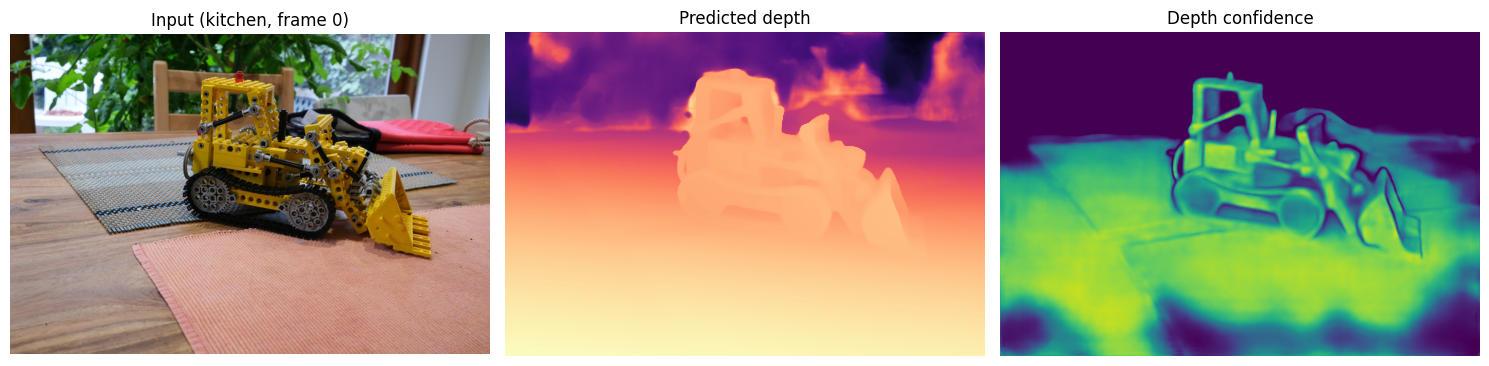

In [19]:
import matplotlib.pyplot as plt
from PIL import Image
from vggt.utils.geometry import unproject_depth_map_to_point_map

model = VGGT.from_pretrained('facebook/VGGT-1B').to(device).eval()

names = sorted(glob.glob(f'{REPO}/examples/kitchen/images/*.png'))
images = load_and_preprocess_images(names).to(device)[None]
with torch.no_grad():
    with torch.autocast('cuda', dtype=dtype):
        tokens, ps_idx = model.aggregator(images)
    pose_enc = model.camera_head(tokens)[-1]
    extrinsic, intrinsic = pose_encoding_to_extri_intri(pose_enc, images.shape[-2:])
    depth_map, depth_conf = model.depth_head(tokens, images, ps_idx)
    point_map, point_conf = model.point_head(tokens, images, ps_idx)
print('frames:', len(names), '| depth', tuple(depth_map.shape), '| points', tuple(point_map.shape),
      '| extrinsic', tuple(extrinsic.shape))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(Image.open(names[0])); ax[0].set_title('Input (kitchen, frame 0)')
ax[1].imshow(depth_map[0, 0, ..., 0].float().cpu(), cmap='magma_r'); ax[1].set_title('Predicted depth')
ax[2].imshow(depth_conf[0, 0].float().cpu(), cmap='viridis'); ax[2].set_title('Depth confidence')
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/phase1_kitchen.png', dpi=150); plt.show()

del model, tokens; torch.cuda.empty_cache()

# Part C — Data (run once, saved on Drive)
### C1. Virtual KITTI 2: train (4 scenes) and validation (Scene02)
Checks the scenes on Drive. Missing ones are extracted from the raw tars on Drive. Then everything is copied to the fast local disk, and the stale `sequence_list.txt` cache is removed.

In [27]:
TRAIN_SCENES = ['Scene01', 'Scene06', 'Scene18', 'Scene20']
VAL_SCENES   = ['Scene02']
SPLITS = {'vkitti_train': TRAIN_SCENES, 'vkitti_val': VAL_SCENES}
PACKED = f'{DATA_DRIVE}/vkitti_prepared.tar'      # one big file = fast to copy

def scene_ok(root, s):
    b = f'{root}/{s}/clone'
    n_rgb = len(glob.glob(f'{b}/frames/rgb/Camera_0/*.jpg'))
    n_dep = len(glob.glob(f'{b}/frames/depth/Camera_0/*.png'))
    return os.path.exists(f'{b}/intrinsic.txt') and os.path.exists(f'{b}/extrinsic.txt') and n_rgb > 0 and n_rgb == n_dep, n_rgb, n_dep

if os.path.exists(PACKED):
    # ---------- FAST PATH (every session after the first) ----------
    print('Restoring from', PACKED)
    shutil.rmtree(VKITTI_TRAIN, ignore_errors=True); shutil.rmtree(VKITTI_VAL, ignore_errors=True)
    subprocess.run(['tar', '-xf', PACKED, '-C', '/content'], check=True)
else:
    # ---------- SLOW PATH (first time only) ----------
    missing = []
    for split, scenes in SPLITS.items():
        for s in scenes:
            ok, n_rgb, n_dep = scene_ok(f'{DATA_DRIVE}/{split}', s)
            print(f'{split:13s} {s}: {"OK" if ok else "MISSING/INCOMPLETE"}  rgb={n_rgb} depth={n_dep}')
            if not ok: missing.append((split, s))

    if missing:
        print('\nExtracting missing scenes from the raw tars (10-20 min)...')
        tmp = '/content/vkitti_extract'; os.makedirs(tmp, exist_ok=True)
        scenes = [s for _, s in missing]
        subprocess.run(['tar', '-xf', f'{RAW_TARS}/vkitti_rgb.tar', '-C', tmp, '--wildcards'] +
                       [f'{s}/clone/frames/rgb/Camera_0/*' for s in scenes], check=True)
        subprocess.run(['tar', '-xf', f'{RAW_TARS}/vkitti_depth.tar', '-C', tmp, '--wildcards'] +
                       [f'{s}/clone/frames/depth/Camera_0/*' for s in scenes], check=True)
        subprocess.run(['tar', '-xzf', f'{RAW_TARS}/vkitti_textgt.tar.gz', '-C', tmp, '--wildcards'] +
                       [f'{s}/clone/{f}' for s in scenes for f in ('intrinsic.txt', 'extrinsic.txt')], check=True)
        for split, s in missing:
            dst = f'{DATA_DRIVE}/{split}/{s}'
            shutil.rmtree(dst, ignore_errors=True)
            shutil.copytree(f'{tmp}/{s}', dst)
            print('saved to Drive:', dst, scene_ok(f'{DATA_DRIVE}/{split}', s))

    for split, local in [('vkitti_train', VKITTI_TRAIN), ('vkitti_val', VKITTI_VAL)]:
        shutil.rmtree(local, ignore_errors=True)
        shutil.copytree(f'{DATA_DRIVE}/{split}', local, ignore=shutil.ignore_patterns('sequence_list.txt'))

    print('Packing into one file for next sessions...')
    subprocess.run(['tar', '-cf', '/content/vkitti_prepared.tar', '-C', '/content', 'vkitti_train', 'vkitti_val'], check=True)
    shutil.copy('/content/vkitti_prepared.tar', PACKED)
    print('saved', PACKED)

# both paths end here: remove stale cache and show what is ready
for p in [f'{VKITTI_TRAIN}/sequence_list.txt', f'{VKITTI_VAL}/sequence_list.txt']:
    if os.path.exists(p): os.remove(p)
for split, local in [('vkitti_train', VKITTI_TRAIN), ('vkitti_val', VKITTI_VAL)]:
    for s in SPLITS[split]:
        print(f'{split:13s} {s}:', scene_ok(local, s))

Restoring from /content/drive/MyDrive/vggt-depth-finetune/data/vkitti_prepared.tar
vkitti_train  Scene01: (True, 447, 447)
vkitti_train  Scene06: (True, 270, 270)
vkitti_train  Scene18: (True, 339, 339)
vkitti_train  Scene20: (True, 837, 837)
vkitti_val    Scene02: (True, 233, 233)


### C2. Real KITTI subset (3 drives)
`remotezip` reads **only the needed files** from inside the remote archives: the LiDAR ground-truth depth (left colour camera) and the matching RGB frames. Drives already on Drive are skipped.

In [28]:
from remotezip import RemoteZip
BASE = 'https://s3.eu-central-1.amazonaws.com/avg-kitti'
DRIVES = ['2011_09_26_drive_0002', '2011_09_26_drive_0005', '2011_09_26_drive_0013']

def extract_matching(url, must_contain, out_dir):
    os.makedirs(out_dir, exist_ok=True)
    with RemoteZip(url) as z:
        members = [m for m in z.infolist() if must_contain in m.filename and m.filename.endswith('.png')]
        for m in members:
            target = os.path.join(out_dir, os.path.basename(m.filename))
            if not os.path.exists(target):          # files already downloaded are skipped
                with z.open(m) as src, open(target, 'wb') as dst:
                    dst.write(src.read())
    return len(members)

for d in DRIVES:
    gt_dir  = f'{KITTI_ROOT}/depth/{d}_sync/proj_depth/groundtruth/image_02'
    rgb_dir = f'{KITTI_ROOT}/raw/{d}_sync/image_02/data'
    done_flag = f'{KITTI_ROOT}/{d}.DONE'
    if os.path.exists(done_flag):
        print(d, 'already complete on Drive'); continue
    print(d, '(downloading / resuming)')
    n_gt  = extract_matching(f'{BASE}/data_depth_annotated.zip', f'{d}_sync/proj_depth/groundtruth/image_02/', gt_dir)
    n_rgb = extract_matching(f'{BASE}/raw_data/{d}/{d}_sync.zip', f'{d}_sync/image_02/data/', rgb_dir)
    print(f'   GT depth maps: {n_gt} | RGB frames: {n_rgb}')
    if n_gt > 0 and n_rgb > 0:
        open(done_flag, 'w').write('ok')

2011_09_26_drive_0002 already complete on Drive
2011_09_26_drive_0005 already complete on Drive
2011_09_26_drive_0013 already complete on Drive


# Part D — Evaluation code (every session)
- **Multi-view:** consecutive frames are grouped into windows of `n_views`; every frame is evaluated.
- **Resolution:** default VGGT preprocessing (width 518), the same as training; prediction resized back to the GT resolution.
- **Scale:** per-frame median scaling (VGGT depth is up to scale).
- **Valid pixels:** 0.001–80 m; for KITTI also the standard Garg crop.
- **Metrics:** AbsRel, SqRel, RMSE, RMSE log, δ<1.25, δ<1.25², δ<1.25³.

In [29]:
# ---------------------------------------------------------------
# Depth evaluation helpers for VGGT on KITTI and Virtual KITTI 2
# ---------------------------------------------------------------
import os, glob, json
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

MIN_DEPTH, MAX_DEPTH = 1e-3, 80.0   # standard KITTI evaluation range (metres)


# ---------- ground-truth readers ----------
def read_kitti_depth(path):
    """KITTI depth PNG: uint16, depth[m] = value / 256, 0 = no LiDAR point."""
    d = np.array(Image.open(path), dtype=np.float32) / 256.0
    return d  # 0 means invalid


def read_vkitti_depth(path):
    """Virtual KITTI 2 depth PNG: uint16 in centimetres (65535 = sky / far)."""
    d = np.array(Image.open(path), dtype=np.float32) / 100.0
    return d


# ---------- sample lists ----------
def kitti_samples(kitti_root, drive, max_frames=None):
    """Return [(rgb_path, gt_path)] for one drive, only frames that have GT."""
    gt_dir = os.path.join(kitti_root, "depth", drive + "_sync",
                          "proj_depth", "groundtruth", "image_02")
    rgb_dir = os.path.join(kitti_root, "raw", drive + "_sync", "image_02", "data")
    out = []
    for gt in sorted(glob.glob(os.path.join(gt_dir, "*.png"))):
        rgb = os.path.join(rgb_dir, os.path.basename(gt))
        if os.path.exists(rgb):
            out.append((rgb, gt))
    return out[:max_frames] if max_frames else out


def vkitti_samples(rgb_root, depth_root=None, scene="Scene02", variation="clone",
                   camera="Camera_0", max_frames=None):
    """Return [(rgb_path, gt_path)] for one Virtual KITTI 2 scene.
    rgb_root / depth_root: folders that contain Scene01, Scene02, ...
    (VKitti2 ships RGB and depth as separate archives; pass the same folder twice if merged)."""
    depth_root = depth_root or rgb_root
    rgb_base = os.path.join(rgb_root, scene, variation, "frames", "rgb", camera)
    dep_base = os.path.join(depth_root, scene, variation, "frames", "depth", camera)
    rgbs = sorted(glob.glob(os.path.join(rgb_base, "*.jpg")))
    out = []
    for rgb in rgbs:
        idx = os.path.basename(rgb).split("_")[-1].split(".")[0]
        gt = os.path.join(dep_base, f"depth_{idx}.png")
        if os.path.exists(gt):
            out.append((rgb, gt))
    return out[:max_frames] if max_frames else out


def make_windows(samples, n_views, max_windows=None):
    """Split consecutive frames into non-overlapping windows of n_views."""
    wins = [samples[i:i + n_views] for i in range(0, len(samples) - n_views + 1, n_views)]
    return wins[:max_windows] if max_windows else wins


# ---------- metrics ----------
def garg_crop_mask(h, w):
    """Standard Garg/Eigen crop used for KITTI (removes regions without LiDAR)."""
    m = np.zeros((h, w), dtype=bool)
    m[int(0.40810811 * h):int(0.99189189 * h), int(0.03594771 * w):int(0.96405229 * w)] = True
    return m


def compute_metrics(pred, gt, use_garg_crop):
    """pred, gt: HxW arrays in the same resolution. Per-frame median scaling."""
    valid = (gt > MIN_DEPTH) & (gt < MAX_DEPTH) & np.isfinite(pred) & (pred > 0)
    if use_garg_crop:
        valid &= garg_crop_mask(*gt.shape)
    if valid.sum() < 10:
        return None
    p, g = pred[valid], gt[valid]
    scale = np.median(g) / np.median(p)          # VGGT depth is up to scale
    p = np.clip(p * scale, MIN_DEPTH, MAX_DEPTH)
    ratio = np.maximum(p / g, g / p)
    return {
        "abs_rel": float(np.mean(np.abs(p - g) / g)),
        "sq_rel": float(np.mean((p - g) ** 2 / g)),
        "rmse": float(np.sqrt(np.mean((p - g) ** 2))),
        "rmse_log": float(np.sqrt(np.mean((np.log(p) - np.log(g)) ** 2))),
        "d1": float(np.mean(ratio < 1.25)),
        "d2": float(np.mean(ratio < 1.25 ** 2)),
        "d3": float(np.mean(ratio < 1.25 ** 3)),
        "n_pixels": int(valid.sum()),
    }


def mean_metrics(rows):
    keys = ["abs_rel", "sq_rel", "rmse", "rmse_log", "d1", "d2", "d3"]
    return {k: float(np.mean([r[k] for r in rows])) for k in keys} | {"n_frames": len(rows)}


# ---------- model inference ----------
@torch.no_grad()
def predict_depth(model, image_paths, device, dtype, load_fn):
    """Run VGGT on one window of frames; return list of depth maps (h x w, model res)."""
    images = load_fn(image_paths).to(device)          # (S, 3, H, W)
    with torch.autocast(device_type="cuda", dtype=dtype, enabled=(device == "cuda")):
        tokens, ps_idx = model.aggregator(images[None])
    depth, conf = model.depth_head(tokens, images[None], ps_idx)   # (1,S,H,W,1), (1,S,H,W)
    depth = depth[0, ..., 0].float().cpu()
    conf = conf[0].float().cpu()
    return depth, conf


def upsample_to(depth_hw, h, w):
    """Resize a model-resolution depth map back to the ground-truth resolution."""
    return F.interpolate(depth_hw[None, None], size=(h, w), mode="bilinear",
                         align_corners=False)[0, 0].numpy()


def evaluate(model, windows, read_gt, device, dtype, load_fn, use_garg_crop, verbose=True):
    """Evaluate every frame of every window. Returns (mean metrics, per-frame rows)."""
    rows = []
    for wi, win in enumerate(windows):
        depth, _ = predict_depth(model, [r for r, _ in win], device, dtype, load_fn)
        for k, (rgb, gt_path) in enumerate(win):
            gt = read_gt(gt_path)
            pred = upsample_to(depth[k], *gt.shape)
            m = compute_metrics(pred, gt, use_garg_crop)
            if m is not None:
                rows.append(m | {"frame": os.path.basename(gt_path), "window": wi})
        if verbose and (wi + 1) % 5 == 0:
            print(f"  window {wi + 1}/{len(windows)}  running AbsRel = "
                  f"{np.mean([r['abs_rel'] for r in rows]):.4f}")
    return mean_metrics(rows), rows


In [30]:
N_VIEWS = 8
MAX_FRAMES_PER_DRIVE = 64      # divisible by 2, 4, 8, 16 -> same frames in every ablation setting
VKITTI_MAX_FRAMES = 160

kitti_by_drive = {d: kitti_samples(KITTI_ROOT, d, MAX_FRAMES_PER_DRIVE) for d in DRIVES}
for d, s in kitti_by_drive.items():
    print(f'{d}: {len(s)} frames with GT')
vk = vkitti_samples(VKITTI_VAL, VKITTI_VAL, 'Scene02', max_frames=VKITTI_MAX_FRAMES)
print(f'VKitti Scene02: {len(vk)} frames')

def run_kitti(model, n_views, tag):
    rows = []
    for d in DRIVES:
        _, r = evaluate(model, make_windows(kitti_by_drive[d], n_views), read_kitti_depth,
                        device, dtype, load_and_preprocess_images, use_garg_crop=True, verbose=False)
        rows += [x | {'drive': d} for x in r]
    res = mean_metrics(rows) | {'n_views': n_views, 'dataset': 'kitti', 'model': tag}
    json.dump({'summary': res, 'frames': rows}, open(f'{RESULTS_DIR}/{tag}_kitti_v{n_views}.json', 'w'), indent=1)
    return res

def run_vkitti(model, n_views, tag):
    _, rows = evaluate(model, make_windows(vk, n_views), read_vkitti_depth,
                       device, dtype, load_and_preprocess_images, use_garg_crop=False, verbose=False)
    res = mean_metrics(rows) | {'n_views': n_views, 'dataset': 'vkitti_scene02', 'model': tag}
    json.dump({'summary': res, 'frames': rows}, open(f'{RESULTS_DIR}/{tag}_vkitti_v{n_views}.json', 'w'), indent=1)
    return res

def show(res):
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in res.items()})

2011_09_26_drive_0002: 64 frames with GT
2011_09_26_drive_0005: 64 frames with GT
2011_09_26_drive_0013: 64 frames with GT
VKitti Scene02: 160 frames


# Part E — Baseline evaluation (pretrained VGGT)

In [20]:
model = VGGT.from_pretrained('facebook/VGGT-1B').to(device).eval()

# save the pretrained weights once: the trainer starts fine-tuning from this file
if not os.path.exists(PRETRAINED_CKPT):
    torch.save(model.state_dict(), PRETRAINED_CKPT)
    print('saved pretrained weights to', PRETRAINED_CKPT)

### E1. Sanity check on one real-KITTI frame (figure for the report)

{'abs_rel': 0.0317, 'sq_rel': 0.0618, 'rmse': 1.6504, 'rmse_log': 0.0474, 'd1': 0.994, 'd2': 0.9995, 'd3': 1.0, 'n_pixels': 94357}


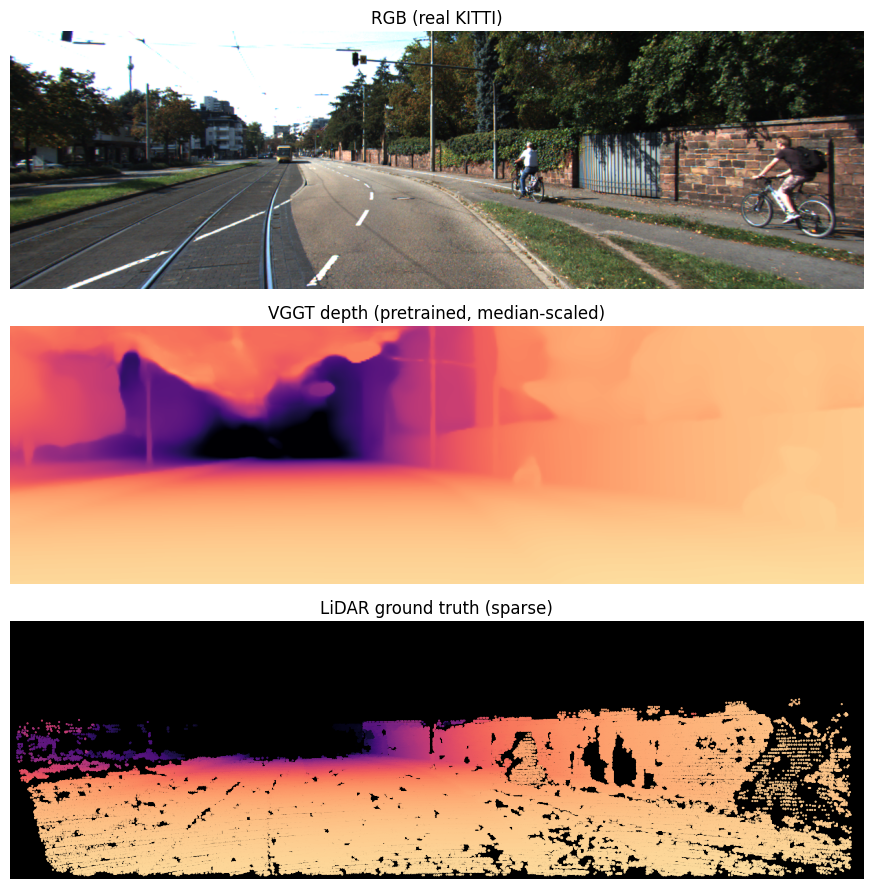

In [21]:
win = make_windows(kitti_by_drive[DRIVES[0]], N_VIEWS)[0]
depth, conf = predict_depth(model, [r for r, _ in win], device, dtype, load_and_preprocess_images)
rgb_path, gt_path = win[0]
gt = read_kitti_depth(gt_path)
pred = upsample_to(depth[0], *gt.shape)
show(compute_metrics(pred, gt, use_garg_crop=True))

valid = gt > 0
pred_scaled = pred * np.median(gt[valid]) / np.median(pred[valid])
ys, xs = np.nonzero(valid)
fig, ax = plt.subplots(3, 1, figsize=(12, 9))
ax[0].imshow(Image.open(rgb_path)); ax[0].set_title('RGB (real KITTI)')
ax[1].imshow(np.clip(pred_scaled, 0, 80), cmap='magma_r', vmin=0, vmax=80); ax[1].set_title('VGGT depth (pretrained, median-scaled)')
ax[2].imshow(np.zeros_like(gt), cmap='gray', vmin=0, vmax=1)
ax[2].scatter(xs, ys, c=gt[valid], s=0.3, cmap='magma_r', vmin=0, vmax=80); ax[2].set_title('LiDAR ground truth (sparse)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/kitti_baseline_example.png', dpi=150); plt.show()

### E2. Baseline ① VKitti Scene02 and ② real KITTI

In [22]:
res_vk_base = run_vkitti(model, N_VIEWS, 'baseline');    show(res_vk_base)
res_kitti_base = run_kitti(model, N_VIEWS, 'baseline');  show(res_kitti_base)

{'abs_rel': 0.0384, 'sq_rel': 0.4814, 'rmse': 4.1449, 'rmse_log': 0.1055, 'd1': 0.9743, 'd2': 0.9851, 'd3': 0.9924, 'n_frames': 160, 'n_views': 8, 'dataset': 'vkitti_scene02', 'model': 'baseline'}
{'abs_rel': 0.0489, 'sq_rel': 0.2327, 'rmse': 2.9316, 'rmse_log': 0.0861, 'd1': 0.9695, 'd2': 0.9933, 'd3': 0.9974, 'n_frames': 192, 'n_views': 8, 'dataset': 'kitti', 'model': 'baseline'}


### E3. Free the GPU before training
Training runs in a **separate process**. A model left in this notebook takes ~5 GB of GPU memory away from it.

In [23]:
import gc
for v in ['model', 'depth', 'conf']:
    globals().pop(v, None)
gc.collect(); torch.cuda.empty_cache()
print(f'GPU memory still allocated here: {torch.cuda.memory_allocated() / 1e9:.2f} GB')

GPU memory still allocated here: 0.17 GB


# Part F — Fine-tuning the depth head (4 VKitti scenes)
### F1. Training config
Written from scratch into the repo's config folder. Key choices:
- aggregator **frozen**, only the depth head trained; camera/point/track heads disabled;
- `img_size: 518` (= evaluation resolution), `aspects: [0.28, 0.34]` (KITTI-like, height/width), `img_nums: [2, 8]`;
- float16 on T4, bfloat16 on A100/L4;
- 5 epochs × 200 steps, learning rate 5e-5 with warm-up + cosine decay;
- checkpoints saved **directly to Drive**; only the latest one is kept (each is several GB).

If training still runs out of memory on a T4, set `MAX_IMG_PER_GPU = 4` and `IMG_NUMS = '[2, 4]'`.

In [31]:
EXP_NAME = 'vkitti4_depth_ft'
MAX_IMG_PER_GPU = 8
IMG_NUMS = '[2, 8]'
AMP_DTYPE = 'bfloat16' if BF16_OK else 'float16'

config = '''defaults:
  - default_dataset.yaml

exp_name: __EXP__
img_size: 518
num_workers: 2
seed_value: 42
accum_steps: 1
patch_size: 14
val_epoch_freq: 1
max_img_per_gpu: __MAXIMG__

limit_train_batches: 200
limit_val_batches: 20

data:
  train:
    _target_: data.dynamic_dataloader.DynamicTorchDataset
    num_workers: ${num_workers}
    max_img_per_gpu: ${max_img_per_gpu}
    common_config:
      img_size: ${img_size}
      patch_size: ${patch_size}
      debug: False
      repeat_batch: False
      img_nums: __IMGNUMS__
      augs:
        aspects: [0.28, 0.34]
    dataset:
      _target_: data.composed_dataset.ComposedDataset
      dataset_configs:
        - _target_: data.datasets.vkitti.VKittiDataset
          split: train
          VKitti_DIR: __TRAIN__
          len_train: 800
  val:
    _target_: data.dynamic_dataloader.DynamicTorchDataset
    num_workers: ${num_workers}
    max_img_per_gpu: ${max_img_per_gpu}
    common_config:
      img_size: ${img_size}
      patch_size: ${patch_size}
      debug: False
      img_nums: __IMGNUMS__
      augs:
        aspects: [0.30, 0.30]
    dataset:
      _target_: data.composed_dataset.ComposedDataset
      dataset_configs:
        - _target_: data.datasets.vkitti.VKittiDataset
          split: test
          VKitti_DIR: __VAL__
          len_test: 1

logging:
  log_dir: logs
  log_visuals: False
  log_freq: 10
  log_level_primary: INFO
  log_level_secondary: WARNING
  all_ranks: False
  tensorboard_writer:
    _target_: train_utils.tb_writer.TensorBoardLogger
    path: ${logging.log_dir}/tensorboard
  scalar_keys_to_log:
    train:
      keys_to_log: [loss_objective, loss_conf_depth, loss_reg_depth, loss_grad_depth]
    val:
      keys_to_log: [loss_objective, loss_conf_depth, loss_reg_depth, loss_grad_depth]

checkpoint:
  save_dir: __CKPTDIR__
  save_freq: 0
  resume_checkpoint_path: __PRETRAINED__
  strict: False

loss:
  _target_: loss.MultitaskLoss
  camera: null
  depth:
    weight: 1.0
    gradient_loss_fn: "grad"
    valid_range: 0.98
  point: null
  track: null

optim:
  param_group_modifiers: False
  optimizer:
    _target_: torch.optim.AdamW
    lr: 5e-5
    weight_decay: 0.05
  frozen_module_names:
    - "*aggregator*"
  amp:
    enabled: True
    amp_dtype: __AMP__
  gradient_clip:
    _target_: train_utils.gradient_clip.GradientClipper
    configs:
      - module_name: ["depth"]
        max_norm: 1.0
        norm_type: 2
  options:
    lr:
      - scheduler:
          _target_: fvcore.common.param_scheduler.CompositeParamScheduler
          schedulers:
            - _target_: fvcore.common.param_scheduler.LinearParamScheduler
              start_value: 1e-8
              end_value: 5e-5
            - _target_: fvcore.common.param_scheduler.CosineParamScheduler
              start_value: 5e-5
              end_value: 1e-8
          lengths: [0.05, 0.95]
          interval_scaling: ['rescaled', 'rescaled']
    weight_decay:
      - scheduler:
          _target_: fvcore.common.param_scheduler.ConstantParamScheduler
          value: 0.05

max_epochs: 5

model:
  _target_: vggt.models.vggt.VGGT
  enable_camera: False
  enable_depth: True
  enable_point: False
  enable_track: False

distributed:
  backend: nccl
  comms_dtype: None
  find_unused_parameters: False
  timeout_mins: 30
  gradient_as_bucket_view: True
  bucket_cap_mb: 25
  broadcast_buffers: True

cuda:
  cudnn_deterministic: False
  cudnn_benchmark: False
  allow_tf32: True
'''
for k, v in {'__EXP__': EXP_NAME, '__MAXIMG__': str(MAX_IMG_PER_GPU), '__IMGNUMS__': IMG_NUMS,
             '__TRAIN__': VKITTI_TRAIN, '__VAL__': VKITTI_VAL, '__AMP__': AMP_DTYPE,
             '__CKPTDIR__': f'{CKPT_DIR}/{EXP_NAME}', '__PRETRAINED__': PRETRAINED_CKPT}.items():
    config = config.replace(k, v)
assert '__' not in config.replace('__init__', '')

TRAIN_DIR = f'{REPO}/training'
open(f'{TRAIN_DIR}/config/{EXP_NAME}.yaml', 'w').write(config)
for p in [f'{VKITTI_TRAIN}/sequence_list.txt', f'{VKITTI_VAL}/sequence_list.txt']:
    if os.path.exists(p): os.remove(p)
print('config written:', f'{TRAIN_DIR}/config/{EXP_NAME}.yaml')
print('pretrained weights present:', os.path.exists(PRETRAINED_CKPT))

config written: /content/vggt_repo/training/config/vkitti4_depth_ft.yaml
pretrained weights present: True


### F2. Train
The full log is also saved to Drive (`logs/`). In the output, check that:
- the missing keys reported when loading the pretrained weights are only camera/point/track-head keys,
- the training loss goes down over the epochs.

In [10]:
log_file = f'{LOG_DIR}/{EXP_NAME}_train.log'
!cd {TRAIN_DIR} && PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True torchrun --nproc_per_node=1 launch.py --config {EXP_NAME} 2>&1 | tee {log_file} | grep -E "Train Epoch|Val Epoch|Error|error|missing|Missing" | tail -n 60
print('checkpoints:', glob.glob(f'{CKPT_DIR}/{EXP_NAME}/*'))

INFO 2026-10-15 13:58:30,831 general.py: 117: Train Epoch: [2][     60/1000000] | Batch Time: 0.1945 (0.2365) | Data Time: 0.0115 (0.0279) | Mem (GB): 6.0000 (6.0000) | Time Elapsed: 00d 00h 03m | Loss/train_loss_objective: -0.2609 (-0.1334) | Loss/train_loss_conf_depth: -0.3308 (-0.2385) | Loss/train_loss_reg_depth: 0.0190 (0.0338) | Loss/train_loss_grad_depth: 0.0508 (0.0714) | Grad/depth: 69.6920 (40.0054)
INFO 2026-10-15 13:58:32,973 general.py: 117: Train Epoch: [2][     70/1000000] | Batch Time: 0.2162 (0.2334) | Data Time: 0.0123 (0.0264) | Mem (GB): 6.0000 (6.0000) | Time Elapsed: 00d 00h 03m | Loss/train_loss_objective: -0.2928 (-0.1341) | Loss/train_loss_conf_depth: -0.3813 (-0.2384) | Loss/train_loss_reg_depth: 0.0235 (0.0338) | Loss/train_loss_grad_depth: 0.0649 (0.0704) | Grad/depth: 11.7869 (38.8742)
INFO 2026-10-15 13:58:35,145 general.py: 117: Train Epoch: [2][     80/1000000] | Batch Time: 0.2098 (0.2314) | Data Time: 0.0265 (0.0246) | Mem (GB): 6.0000 (6.0000) | Time 

In [13]:
import re
log = open(f'{LOG_DIR}/{EXP_NAME}_train.log').read()
last = {}
for line in log.splitlines():
    m = re.search(r'Train Epoch: \[(\d+)\]', line)
    if m: last[int(m.group(1))] = line
def avg(line, key):
    m = re.search(rf'{key}: [-\d.]+ \(([-\d.]+)\)', line)
    return float(m.group(1)) if m else None
print('epoch | objective (avg) | reg_depth | grad_depth')
for e in sorted(last):
    l = last[e]
    print(f'{e:5d} | {avg(l, "train_loss_objective"):15.4f} | {avg(l, "train_loss_reg_depth"):9.4f} | {avg(l, "train_loss_grad_depth"):10.4f}')

epoch | objective (avg) | reg_depth | grad_depth
    0 |         -0.0344 |    0.0420 |     0.0760
    1 |         -0.0879 |    0.0391 |     0.0802
    2 |         -0.1316 |    0.0348 |     0.0710
    3 |         -0.1566 |    0.0326 |     0.0712
    4 |         -0.1618 |    0.0322 |     0.0748


# Part G — Fine-tuned evaluation ③ ④
Loads the fine-tuned checkpoint on top of the pretrained model and **checks that the depth head actually changed**.

In [24]:
ckpt_files = sorted(glob.glob(f'{CKPT_DIR}/{EXP_NAME}/checkpoint*'))
print('found:', ckpt_files)
ckpt_path = [f for f in ckpt_files if os.path.basename(f).startswith('checkpoint.')] or ckpt_files
ckpt_path = ckpt_path[0]

model = VGGT.from_pretrained('facebook/VGGT-1B').to(device).eval()
before = {k: v.detach().clone() for k, v in model.depth_head.state_dict().items()}

ckpt = torch.load(ckpt_path, map_location='cpu')
state = ckpt.get('model', ckpt)
state = {k.replace('module.', '', 1): v for k, v in state.items()}
missing, unexpected = model.load_state_dict(state, strict=False)

depth_missing = [k for k in missing if k.startswith('depth_head')]
changed = sum(not torch.equal(before[k], model.depth_head.state_dict()[k].to(before[k].device)) for k in before)
print(f'missing keys: {len(missing)} (depth_head: {len(depth_missing)}) | unexpected: {len(unexpected)}')
print(f'depth_head tensors changed by fine-tuning: {changed}/{len(before)}')
assert not depth_missing and changed > 0, 'Fine-tuned depth head NOT loaded - do not trust the results!'
del before

found: ['/content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft/checkpoint.pt']
missing keys: 525 (depth_head: 0) | unexpected: 0
depth_head tensors changed by fine-tuning: 62/62


In [25]:
res_vk_ft = run_vkitti(model, N_VIEWS, 'finetuned');      show(res_vk_ft)
res_kitti_ft = run_kitti(model, N_VIEWS, 'finetuned');    show(res_kitti_ft)

{'abs_rel': 0.0379, 'sq_rel': 0.4364, 'rmse': 4.0601, 'rmse_log': 0.1039, 'd1': 0.975, 'd2': 0.9855, 'd3': 0.993, 'n_frames': 160, 'n_views': 8, 'dataset': 'vkitti_scene02', 'model': 'finetuned'}
{'abs_rel': 0.0502, 'sq_rel': 0.252, 'rmse': 3.0392, 'rmse_log': 0.0891, 'd1': 0.9675, 'd2': 0.9921, 'd3': 0.9967, 'n_frames': 192, 'n_views': 8, 'dataset': 'kitti', 'model': 'finetuned'}


In [32]:
import gc, re
import matplotlib.pyplot as plt
from PIL import Image

def paired(ds, tag='finetuned', n_views=8):
    b = json.load(open(f'{RESULTS_DIR}/baseline_{ds}_v{n_views}.json'))['frames']
    f = json.load(open(f'{RESULTS_DIR}/{tag}_{ds}_v{n_views}.json'))['frames']
    key = lambda r: (r.get('drive', ''), r['frame'])
    base = {key(r): r['abs_rel'] for r in b}
    d = np.array([r['abs_rel'] - base[key(r)] for r in f if key(r) in base])
    print(f'{tag} / {ds:7s}: {len(d)} frames | mean AbsRel change {d.mean():+.4f} ± {d.std():.4f} '
          f'| better on {(d < 0).mean():.0%} of frames')
    if ds == 'kitti':
        for drv in DRIVES:
            dd = np.array([r['abs_rel'] - base[key(r)] for r in f if r.get('drive') == drv])
            print(f'   {drv}: change {dd.mean():+.4f} | better on {(dd < 0).mean():.0%}')

paired('vkitti'); paired('kitti')

finetuned / vkitti : 160 frames | mean AbsRel change -0.0004 ± 0.0024 | better on 62% of frames
finetuned / kitti  : 192 frames | mean AbsRel change +0.0012 ± 0.0028 | better on 28% of frames
   2011_09_26_drive_0002: change +0.0002 | better on 36%
   2011_09_26_drive_0005: change +0.0024 | better on 20%
   2011_09_26_drive_0013: change +0.0012 | better on 28%


# Part H — View-count ablation and summary
### H1. Ablation on real KITTI (2, 4, 8, 16 views), fine-tuned model
The same 192 frames are evaluated for every setting.

# Part I

### New cell I1: download the validation drives

In [33]:
VAL_DRIVES = ['2011_09_26_drive_0020', '2011_09_26_drive_0036', '2011_09_26_drive_0079']
assert not set(VAL_DRIVES) & set(DRIVES), 'validation and test drives must be different'
assert 'extract_matching' in globals(), 'run C2 first'

for d in VAL_DRIVES:
    gt_dir  = f'{KITTI_ROOT}/depth/{d}_sync/proj_depth/groundtruth/image_02'
    rgb_dir = f'{KITTI_ROOT}/raw/{d}_sync/image_02/data'
    done_flag = f'{KITTI_ROOT}/{d}.DONE'
    if os.path.exists(done_flag):
        print(d, 'already complete on Drive'); continue
    print(d, '(downloading / resuming)')
    n_gt  = extract_matching(f'{BASE}/data_depth_annotated.zip', f'{d}_sync/proj_depth/groundtruth/image_02/', gt_dir)
    n_rgb = extract_matching(f'{BASE}/raw_data/{d}/{d}_sync.zip', f'{d}_sync/image_02/data/', rgb_dir)
    print(f'   GT depth maps: {n_gt} | RGB frames: {n_rgb}')
    if n_gt > 0 and n_rgb > 0:
        open(done_flag, 'w').write('ok')

kitti_val_by_drive = {d: kitti_samples(KITTI_ROOT, d, MAX_FRAMES_PER_DRIVE) for d in VAL_DRIVES}
for d, s in kitti_val_by_drive.items():
    print(f'validation {d}: {len(s)} frames with GT')
    assert len(s) >= N_VIEWS, f'{d}: no usable frames - tell Claude, this drive must be replaced'

2011_09_26_drive_0020 (downloading / resuming)
   GT depth maps: 76 | RGB frames: 86
2011_09_26_drive_0036 (downloading / resuming)
   GT depth maps: 793 | RGB frames: 803
2011_09_26_drive_0079 (downloading / resuming)
   GT depth maps: 90 | RGB frames: 100
validation 2011_09_26_drive_0020: 64 frames with GT
validation 2011_09_26_drive_0036: 64 frames with GT
validation 2011_09_26_drive_0079: 64 frames with GT


### New cell I2a: training config (saves a checkpoint every epoch)

In [34]:
import re
EXP_SEL = 'vkitti4_depth_ft_sel'
LOCAL_CKPT = f'/content/ckpt_{EXP_SEL}'
SEL_EPOCHS, SEL_STEPS = 10, 100

base_cfg = f'{TRAIN_DIR}/config/{EXP_NAME}.yaml'
assert os.path.exists(base_cfg), 'run F1 (the config cell) first in this session'
cfg = open(base_cfg).read()
for old, new in [(f'exp_name: {EXP_NAME}', f'exp_name: {EXP_SEL}'),
                 (f'save_dir: {CKPT_DIR}/{EXP_NAME}', f'save_dir: {LOCAL_CKPT}'),
                 ('save_freq: 0', 'save_freq: 1'),
                 ('limit_train_batches: 200', f'limit_train_batches: {SEL_STEPS}'),
                 ('max_epochs: 5', f'max_epochs: {SEL_EPOCHS}')]:
    assert old in cfg, f'not found in config: {old}'
    cfg = cfg.replace(old, new)
open(f'{TRAIN_DIR}/config/{EXP_SEL}.yaml', 'w').write(cfg)
for p in [f'{VKITTI_TRAIN}/sequence_list.txt', f'{VKITTI_VAL}/sequence_list.txt']:
    if os.path.exists(p): os.remove(p)

free_gb = shutil.disk_usage('/content').free / 1e9
print(f'free local disk: {free_gb:.0f} GB (needs about {SEL_EPOCHS * 5} GB)')
assert free_gb > SEL_EPOCHS * 5 + 5, 'not enough local disk: set SEL_EPOCHS, SEL_STEPS = 5, 200 and rerun this cell'

free local disk: 58 GB (needs about 50 GB)


### New cell I2b: train (about 10 min on the A100)

In [35]:
sel_log = f'{LOG_DIR}/{EXP_SEL}_train.log'
!cd {TRAIN_DIR} && PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True torchrun --nproc_per_node=1 launch.py --config {EXP_SEL} 2>&1 | tee {sel_log} | grep -E "Train Epoch.*\[ *{SEL_STEPS}/|Error|error" | tail -n 40
print(sorted(os.listdir(LOCAL_CKPT)))

I0000 00:00:1792076946.581768   20932 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792076949.034122   20932 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Grad strides do not match bucket view strides. This may indicate grad was not created according to the gradient layout contract, or that the param's strides changed since DDP was constructed.  This is not an error, but may impair performance.
INFO 2026-10-15 15:09:54,707 general.py: 117: Train Epoch: [0][    100/1000000] | Batch Time: 0.1917 (0.2375) | D

### New cell I3: keep only the depth head of each epoch (saved on Drive)

In [36]:
HEAD_DIR = f'{CKPT_DIR}/{EXP_SEL}_heads'
os.makedirs(HEAD_DIR, exist_ok=True)
epoch_of = lambda p: int(re.search(r'checkpoint_(\d+)', os.path.basename(p)).group(1))

for p in sorted(glob.glob(f'{LOCAL_CKPT}/checkpoint_*.pt'), key=epoch_of):
    out = f'{HEAD_DIR}/depth_head_epoch{epoch_of(p)}.pt'
    if not os.path.exists(out):
        sd = torch.load(p, map_location='cpu'); sd = sd.get('model', sd)
        sd = {k.replace('module.', '', 1): v for k, v in sd.items()}
        head = {k[len('depth_head.'):]: v for k, v in sd.items() if k.startswith('depth_head.')}
        assert len(head) > 0, f'no depth_head weights in {p}'
        torch.save(head, out)
        del sd
    os.remove(p)                       # free local disk
    print('saved', out)

heads = {epoch_of(p.replace('depth_head_epoch', 'checkpoint_')): p
         for p in glob.glob(f'{HEAD_DIR}/depth_head_epoch*.pt')}
print('epochs available:', sorted(heads))

saved /content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft_sel_heads/depth_head_epoch0.pt
saved /content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft_sel_heads/depth_head_epoch1.pt
saved /content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft_sel_heads/depth_head_epoch2.pt
saved /content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft_sel_heads/depth_head_epoch3.pt
saved /content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft_sel_heads/depth_head_epoch4.pt
saved /content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft_sel_heads/depth_head_epoch5.pt
saved /content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft_sel_heads/depth_head_epoch6.pt
saved /content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft_sel_heads/depth_head_epoch7.pt
saved /content/drive/MyDrive/vggt-depth-finetune/checkpoints/vkitti4_depth_ft_sel_heads/depth_head_epoch8.pt
saved /content/driv

### New cell I4: choose the best epoch on the validation drives

pretrained  val AbsRel 0.0739 | δ<1.25 0.9279
epoch 0     val AbsRel 0.0726 | δ<1.25 0.9296
epoch 1     val AbsRel 0.0737 | δ<1.25 0.9290
epoch 2     val AbsRel 0.0712 | δ<1.25 0.9310
epoch 3     val AbsRel 0.0763 | δ<1.25 0.9261
epoch 4     val AbsRel 0.0767 | δ<1.25 0.9240
epoch 5     val AbsRel 0.0759 | δ<1.25 0.9292
epoch 6     val AbsRel 0.0733 | δ<1.25 0.9279
epoch 7     val AbsRel 0.0743 | δ<1.25 0.9272
epoch 8     val AbsRel 0.0746 | δ<1.25 0.9274
epoch 9     val AbsRel 0.0744 | δ<1.25 0.9275

best on validation: epoch 2


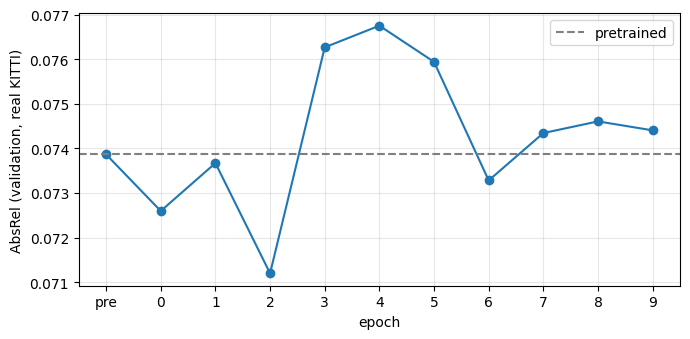

In [37]:
def eval_drives(model, drives, n_views=N_VIEWS):
    rows = []
    for d, s in drives.items():
        _, r = evaluate(model, make_windows(s, n_views), read_kitti_depth, device, dtype,
                        load_and_preprocess_images, use_garg_crop=True, verbose=False)
        rows += r
    return mean_metrics(rows)

model = VGGT.from_pretrained('facebook/VGGT-1B').to(device).eval()
pretrained_head = {k: v.detach().clone() for k, v in model.depth_head.state_dict().items()}

candidates = {-1: None} | {e: heads[e] for e in sorted(heads)}      # -1 = pretrained
val_res = {}
for e, path in candidates.items():
    model.depth_head.load_state_dict(pretrained_head if path is None else torch.load(path, map_location='cpu'))
    val_res[e] = eval_drives(model, kitti_val_by_drive)
    name = 'pretrained' if e == -1 else f'epoch {e}'
    print(f'{name:10s}  val AbsRel {val_res[e]["abs_rel"]:.4f} | δ<1.25 {val_res[e]["d1"]:.4f}')

best_epoch = min(val_res, key=lambda e: val_res[e]['abs_rel'])
print('\nbest on validation:', 'pretrained' if best_epoch == -1 else f'epoch {best_epoch}')
json.dump({str(e): r for e, r in val_res.items()} | {'best_epoch': best_epoch},
          open(f'{RESULTS_DIR}/selection_val_kitti.json', 'w'), indent=1)

es = sorted(val_res)
plt.figure(figsize=(7, 3.5))
plt.plot(es, [val_res[e]['abs_rel'] for e in es], marker='o')
plt.xticks(es, ['pre'] + [str(e) for e in es[1:]])
plt.axhline(val_res[-1]['abs_rel'], ls='--', c='gray', label='pretrained')
plt.xlabel('epoch'); plt.ylabel('AbsRel (validation, real KITTI)'); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/selection_val_curve.png', dpi=150); plt.show()

### New cell I5: test the chosen one on the test sets

In [38]:
path = candidates[best_epoch]
model.depth_head.load_state_dict(pretrained_head if path is None else torch.load(path, map_location='cpu'))
print('testing:', 'pretrained' if best_epoch == -1 else f'epoch {best_epoch}')
res_kitti_sel = run_kitti(model, N_VIEWS, 'selected');   show(res_kitti_sel)
res_vk_sel    = run_vkitti(model, N_VIEWS, 'selected');  show(res_vk_sel)
paired('kitti', 'selected'); paired('vkitti', 'selected')

testing: epoch 2
{'abs_rel': 0.0469, 'sq_rel': 0.229, 'rmse': 2.817, 'rmse_log': 0.0845, 'd1': 0.9719, 'd2': 0.9926, 'd3': 0.9968, 'n_frames': 192, 'n_views': 8, 'dataset': 'kitti', 'model': 'selected'}
{'abs_rel': 0.0435, 'sq_rel': 0.4573, 'rmse': 4.1572, 'rmse_log': 0.1065, 'd1': 0.9746, 'd2': 0.9856, 'd3': 0.9931, 'n_frames': 160, 'n_views': 8, 'dataset': 'vkitti_scene02', 'model': 'selected'}
selected / kitti  : 192 frames | mean AbsRel change -0.0020 ± 0.0044 | better on 73% of frames
   2011_09_26_drive_0002: change -0.0044 | better on 100%
   2011_09_26_drive_0005: change +0.0031 | better on 19%
   2011_09_26_drive_0013: change -0.0048 | better on 100%
selected / vkitti : 160 frames | mean AbsRel change +0.0052 ± 0.0028 | better on 2% of frames


pretrained  val 0.0739 | test 0.0489
epoch 0     val 0.0726 | test 0.0494
epoch 1     val 0.0737 | test 0.0515
epoch 2     val 0.0712 | test 0.0469
epoch 3     val 0.0763 | test 0.0522
epoch 4     val 0.0767 | test 0.0505
epoch 5     val 0.0759 | test 0.0526
epoch 6     val 0.0733 | test 0.0475
epoch 7     val 0.0743 | test 0.0493
epoch 8     val 0.0746 | test 0.0492
epoch 9     val 0.0744 | test 0.0490
correlation val-test: 0.74


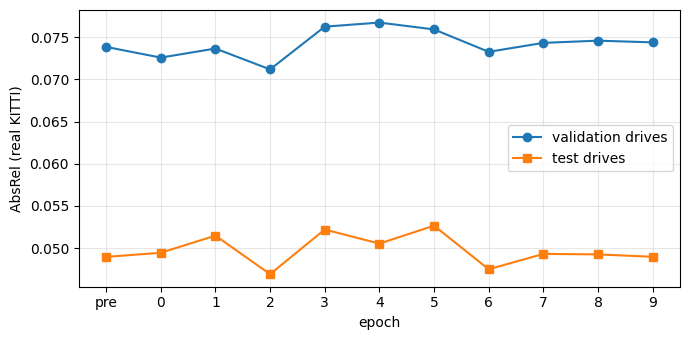

In [39]:
test_curve = {}
for e, path in candidates.items():
    model.depth_head.load_state_dict(pretrained_head if path is None else torch.load(path, map_location='cpu'))
    test_curve[e] = eval_drives(model, kitti_by_drive)
    print(f'{"pretrained" if e == -1 else f"epoch {e}":10s}  val {val_res[e]["abs_rel"]:.4f} | test {test_curve[e]["abs_rel"]:.4f}')
json.dump({str(e): r for e, r in test_curve.items()}, open(f'{RESULTS_DIR}/selection_test_curve.json', 'w'), indent=1)
print('correlation val-test:', round(np.corrcoef([val_res[e]['abs_rel'] for e in es], [test_curve[e]['abs_rel'] for e in es])[0, 1], 2))

plt.figure(figsize=(7, 3.5))
plt.plot(es, [val_res[e]['abs_rel'] for e in es], marker='o', label='validation drives')
plt.plot(es, [test_curve[e]['abs_rel'] for e in es], marker='s', label='test drives')
plt.xticks(es, ['pre'] + [str(e) for e in es[1:]])
plt.xlabel('epoch'); plt.ylabel('AbsRel (real KITTI)'); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/selection_val_vs_test.png', dpi=150); plt.show()

# New H Part

### Cell 1: run the ablation (about 10 minutes)

In [40]:
model.depth_head.load_state_dict(torch.load(candidates[best_epoch], map_location='cpu'))
ablation = {'selected': {n: run_kitti(model, n, 'selected') for n in [2, 4, 8, 16]}}

model.depth_head.load_state_dict(pretrained_head)
ablation['baseline'] = {n: run_kitti(model, n, 'baseline') for n in [2, 4, 8, 16]}

for tag in ablation:
    print(tag, {n: round(r['abs_rel'], 4) for n, r in ablation[tag].items()})

selected {2: 0.0546, 4: 0.0511, 8: 0.0469, 16: 0.0444}
baseline {2: 0.0587, 4: 0.0541, 8: 0.0489, 16: 0.045}


### Cell 2: draw the plot

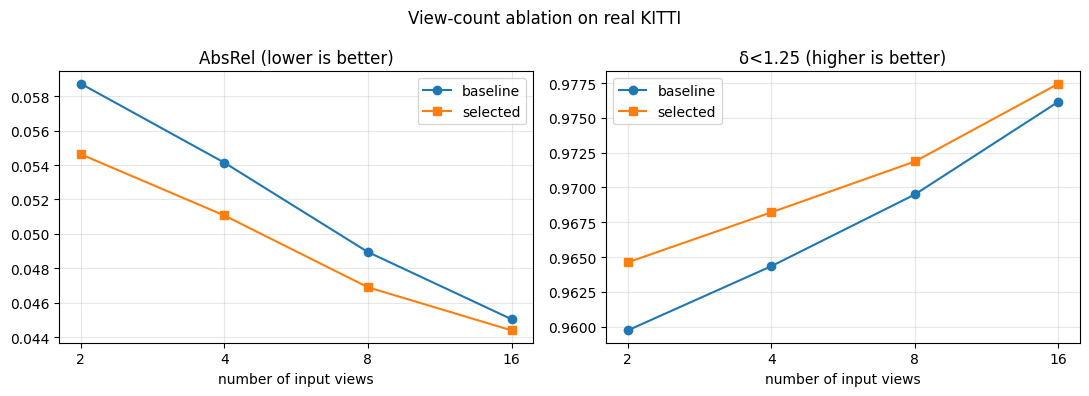

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for tag, marker in [('baseline', 'o'), ('selected', 's')]:
    ns = sorted(ablation[tag])
    ax[0].plot(ns, [ablation[tag][n]['abs_rel'] for n in ns], marker=marker, label=tag)
    ax[1].plot(ns, [ablation[tag][n]['d1'] for n in ns], marker=marker, label=tag)
for a, t in zip(ax, ['AbsRel (lower is better)', 'δ<1.25 (higher is better)']):
    a.set_xscale('log', base=2); a.set_xticks([2, 4, 8, 16]); a.set_xticklabels([2, 4, 8, 16])
    a.set_xlabel('number of input views'); a.set_title(t); a.grid(alpha=.3); a.legend()
plt.suptitle('View-count ablation on real KITTI'); plt.tight_layout()
plt.savefig(f'{FIG_DIR}/view_ablation_kitti.png', dpi=150); plt.show()

In [42]:
import pandas as pd
cols = ['dataset', 'model', 'n_views', 'n_frames', 'abs_rel', 'sq_rel', 'rmse', 'rmse_log', 'd1', 'd2', 'd3']
rows = [json.load(open(f'{RESULTS_DIR}/{m}_{ds}_v8.json'))['summary']
        for ds in ['vkitti', 'kitti'] for m in ['baseline', 'finetuned', 'selected']]
summary = pd.DataFrame(rows)[cols].round(4)
summary.to_csv(f'{RESULTS_DIR}/summary.csv', index=False)
summary

,dataset,model,n_views,n_frames,abs_rel,sq_rel,rmse,rmse_log,d1,d2,d3
0,vkitti_scene02,baseline,8,160,0.0384,0.4814,4.1449,0.1055,0.9743,0.9851,0.9924
1,vkitti_scene02,finetuned,8,160,0.0379,0.4364,4.0601,0.1039,0.9750,0.9855,0.9930
2,vkitti_scene02,selected,8,160,0.0435,0.4573,4.1572,0.1065,0.9746,0.9856,0.9931
3,kitti,baseline,8,192,0.0489,0.2327,2.9316,0.0861,0.9695,0.9933,0.9974
4,kitti,finetuned,8,192,0.0502,0.2520,3.0392,0.0891,0.9675,0.9921,0.9967
5,kitti,selected,8,192,0.0469,0.2290,2.8170,0.0845,0.9719,0.9926,0.9968
